# Task 1A + 1B: Understanding Beijing's PM2.5 data

## Problem definition

PM2.5 means airborne particles smaller than 2.5 micrometres, about 30 times thinner than a human hair. They're small enough to get deep into the lungs and bloodstream, and long exposure is linked to heart and lung disease. Beijing has had some of the worst PM2.5 levels of any major city, with winter smog episodes reaching several hundred µg/m³.

**Our problem:** forecast **next hour's PM2.5 level** from the last 24 hours of pollution and the latest weather. A one-hour warning gives people, schools and hospitals time to act (stay indoors, close windows, move outdoor activities) before the bad air arrives.

**Why this dataset**
- **A long, regular record:** 5 years of hourly readings from one fixed monitor at the US Embassy, which is a trusted source
- **The target and its drivers in one file:** PM2.5 sits alongside the weather that drives it (wind, humidity, pressure, rain, snow)
- **Real-world mess:** it has genuine missing values, which lets us show proper preprocessing
- **Open and citable:** [Kaggle](https://www.kaggle.com/datasets/djhavera/beijing-pm25-data-data-set), originally from the [UCI ML Repository](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data) (CC BY 4.0); Liang et al. (2015), *Proceedings of the Royal Society A*

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from load_data import load_raw

FIG_DIR = ROOT / "outputs" / "figures"
plt.rcParams["figure.figsize"] = (11, 4)
sns.set_theme(style="whitegrid")

def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"eda_{name}.png", dpi=150)
    plt.show()

raw = load_raw()
raw.head()

,datetime,pm25,dew_point,temperature,pressure,wind_dir,wind_speed,hours_snow,hours_rain
0,2010-01-01 00:00:00,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2010-01-01 01:00:00,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,2010-01-01 02:00:00,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,2010-01-01 03:00:00,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,2010-01-01 04:00:00,NaN,-20,-12.0,1018.0,NW,12.97,0,0


## 1. Time range and frequency

In [2]:
gaps = raw.datetime.diff().value_counts()

print(f"From {raw.datetime.min()} to {raw.datetime.max()}")
print(f"{len(raw):,} rows over {raw.datetime.dt.year.nunique()} years")
print("Time step between rows:")
print(gaps)

From 2010-01-01 00:00:00 to 2014-12-31 23:00:00
43,824 rows over 5 years
Time step between rows:
datetime
0 days 01:00:00    43823
Name: count, dtype: int64


- **Range:** 1 Jan 2010 to 31 Dec 2014, which is 5 full years.
- **Frequency:** hourly. Every gap between rows is exactly 1 hour, so **no timestamps are missing**, only some values. That's important: lag features like "1 hour ago" or "24 hours ago" can be made with a simple shift and will always mean the right time.

## 2. Summary statistics

In [3]:
num_cols = ["pm25", "dew_point", "temperature", "pressure", "wind_speed", "hours_snow", "hours_rain"]
stats = raw[num_cols].describe().T
stats["skew"] = raw[num_cols].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
pm25,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,994.0,1.80
dew_point,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,28.0,-0.15
temperature,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,42.0,-0.16
pressure,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1046.0,0.10
wind_speed,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,585.6,4.30
hours_snow,43824.0,0.05,0.76,0.00,0.00,0.00,0.00,27.0,19.48
hours_rain,43824.0,0.19,1.42,0.00,0.00,0.00,0.00,36.0,11.66


In [4]:
print("Wind direction counts:")
print(raw.wind_dir.value_counts())
print(f"\nHours with no snow: {(raw.hours_snow == 0).mean():.1%}, no rain: {(raw.hours_rain == 0).mean():.1%}")
print(f"Hours with PM2.5 above 75 µg/m³ (China's 24-hour limit): {(raw.pm25 > 75).mean():.1%}")
print(f"Hours above 250 µg/m³ (hazardous): {(raw.pm25 > 250).mean():.1%}")

Wind direction counts:
wind_dir
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64

Hours with no snow: 99.2%, no rain: 95.9%
Hours with PM2.5 above 75 µg/m³ (China's 24-hour limit): 46.2%
Hours above 250 µg/m³ (hazardous): 7.0%


## 3. Distributions

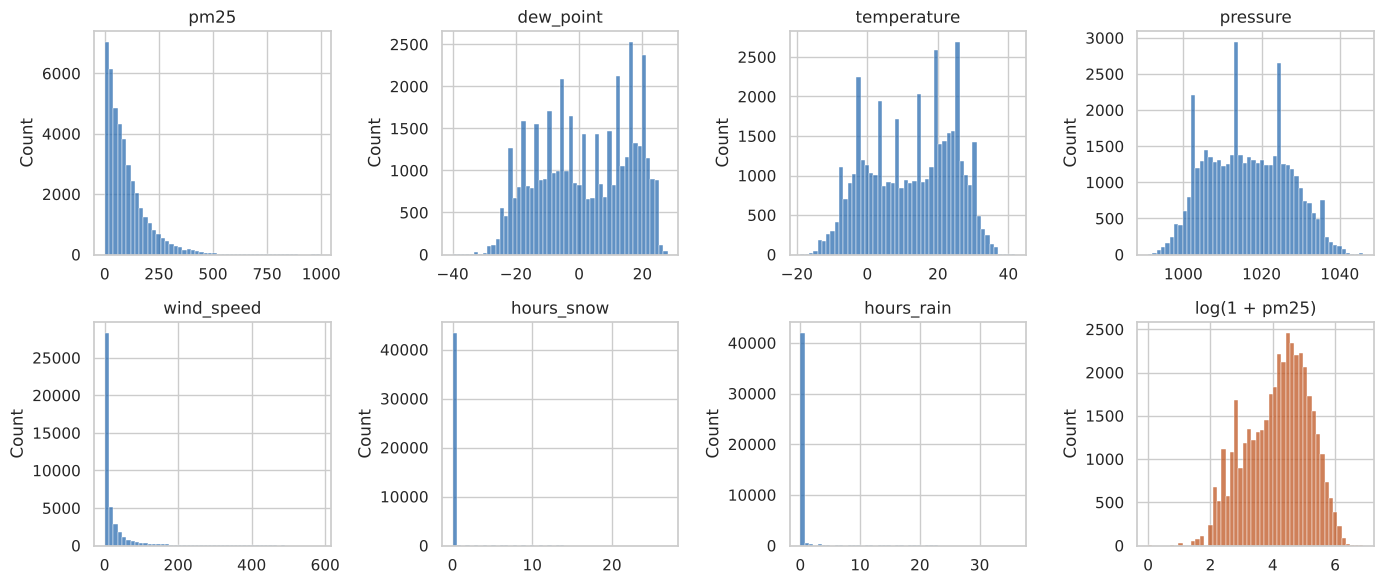

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(raw[col].dropna(), bins=50, ax=ax, color="#2b6cb0")
    ax.set_title(col)
    ax.set_xlabel("")
sns.histplot(np.log1p(raw.pm25.dropna()), bins=50, ax=axes.flat[-1], color="#c05621")
axes.flat[-1].set_title("log(1 + pm25)")
axes.flat[-1].set_xlabel("")
save("distributions")

**What the distributions show**

- **PM2.5 is strongly right-skewed (skew 1.8).** The median is 72 µg/m³ but the mean is 99, pulled up by smog spikes reaching 994. On a log scale it looks roughly bell-shaped. The extreme values are real smog events, not errors, so we **keep them**: they're exactly the hours a warning system exists for.
- **The air is often unhealthy.** 46% of hours are above 75 µg/m³, China's 24-hour limit, and 7% are above 250.
- **Temperature, dew point and pressure** have a broad two-peaked shape, from summer versus winter.
- **Wind speed is cumulative.** The column adds up speed for as long as the direction stays the same, which is why it has a long tail up to 585. It still works as "how long and how hard has the wind been blowing".
- **Snow and rain are almost always zero** (99.2% and 95.9% of hours), so on their own they'll carry little signal.